In [ ]:
import numpy as np
import soundfile as sf
import librosa
import noisereduce as nr
from scipy.signal import butter, sosfiltfilt

def butter_bandpass(low_hz, high_hz, sr, order=6):
    """Thiết kế bộ lọc band-pass."""
    nyq = 0.5 * sr
    low = low_hz / nyq
    high = high_hz / nyq
    sos = butter(order, [low, high], btype="bandpass", output="sos")
    return sos

def apply_bandpass(data, low_hz, high_hz, sr):
    """Áp dụng bộ lọc band-pass cho dữ liệu âm thanh."""
    sos = butter_bandpass(low_hz, high_hz, sr)
    # Áp dụng cho cả mono và stereo
    if data.ndim == 1:
        return sosfiltfilt(sos, data)
    else:
        return np.array([sosfiltfilt(sos, data[ch]) for ch in range(data.shape[0])])

def process_audio_pipeline(input_path, output_path):
    print(f"--- Đang bắt đầu xử lý: {input_path} ---")
    
    # 1. Load file
    data, sr = librosa.load(input_path, sr=None, mono=True) # Ép về mono để noisereduce hoạt động tốt nhất
    
    # 2. Bước 1: Bandpass Filter (80Hz - 8000Hz)
    print("Đang áp dụng Bandpass Filter...")
    filtered_bp = apply_bandpass(data, low_hz=80, high_hz=8000, sr=sr)
    
    # 3. Bước 2: Spectral Gating
    print("Đang thực hiện Spectral Gating...")
    reduced_noise = nr.reduce_noise(
        y=filtered_bp, 
        sr=sr, 
        stationary=False,   # Do nhiễu không ổn định (xe cộ, tiếng ồn đường phố)
        prop_decrease=0.85 # Giữ lại 15% nhiễu để âm thanh tự nhiên, không bị robot
    )
    
    # 4. Bước 3: RMS Matching
    print("Đang cân bằng âm lượng (RMS Matching)...")
    original_rms = np.sqrt(np.mean(data**2))
    reduced_rms = np.sqrt(np.mean(reduced_noise**2))
    if reduced_rms > 0:
        final_audio = reduced_noise * (original_rms / reduced_rms)
    else:
        final_audio = reduced_noise

    # 5. Xuất file
    sf.write(output_path, final_audio, sr)
    print(f"--- Hoàn tất! File đã lưu tại: {output_path} ---")

if __name__ == "__main__":
    INPUT_FILE = "audio.wav"
    OUTPUT_FILE = "audio_clean.wav"
    
    try:
        process_audio_pipeline(INPUT_FILE, OUTPUT_FILE)
    except Exception as e:
        print(f"Có lỗi xảy ra: {e}")

--- Đang bắt đầu xử lý: audio.wav ---
Đang áp dụng Bandpass Filter...
Đang thực hiện Spectral Gating...
Đang cân bằng âm lượng (RMS Matching)...
--- Hoàn tất! File đã lưu tại: audio_clean.wav ---


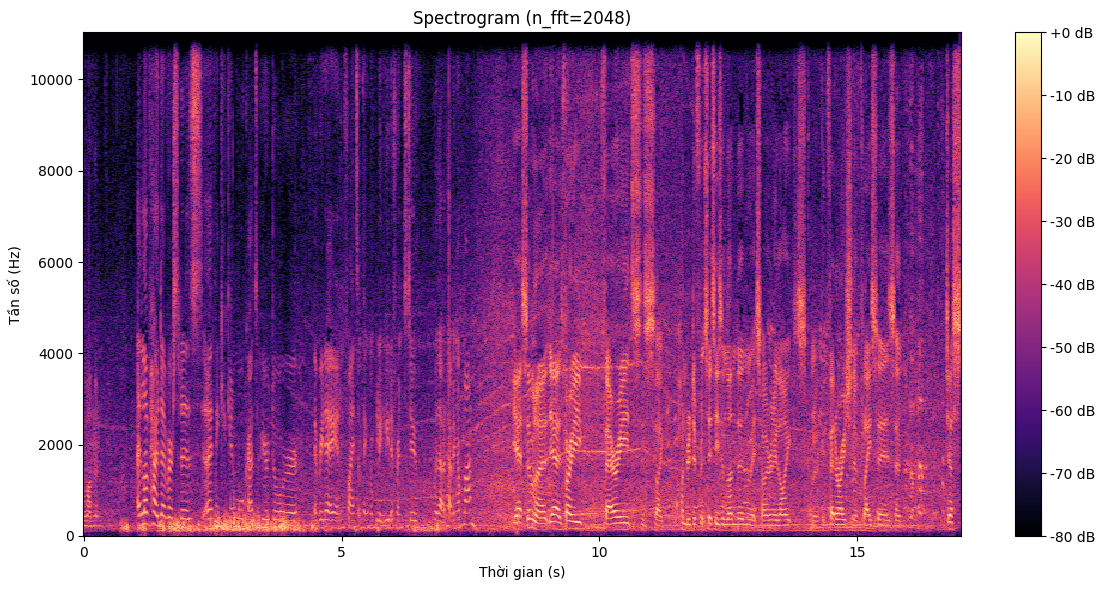

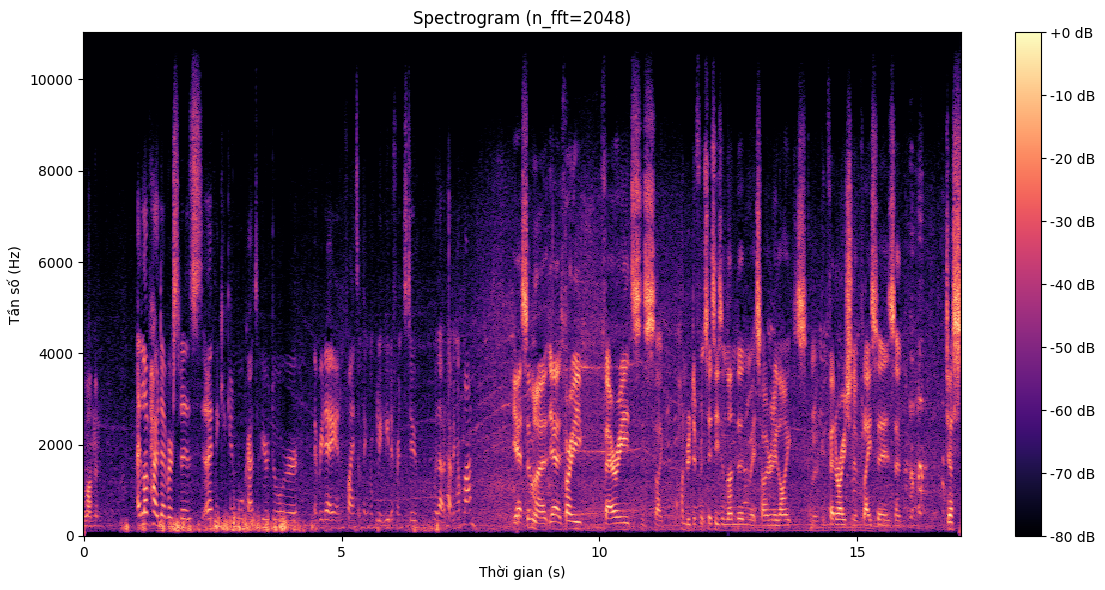

In [7]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

def plot_spectrogram(file_path, n_fft=2048):
    y, sr = librosa.load(file_path)
    stft = librosa.stft(y, n_fft=n_fft, hop_length=n_fft//4)
    s_db = librosa.amplitude_to_db(np.abs(stft), ref=np.max)
    plt.figure(figsize=(12, 6))
    librosa.display.specshow(s_db, sr=sr, hop_length=n_fft//4, 
                             x_axis='time', y_axis='hz', cmap='magma')
    plt.colorbar(format='%+2.0f dB')
    plt.title(f'Spectrogram (n_fft={n_fft})')
    plt.xlabel('Thời gian (s)')
    plt.ylabel('Tần số (Hz)')
    plt.tight_layout()
    plt.savefig(f'spectrogram_{file_path.split(".")[0]}.png')
    plt.show()
    
plot_spectrogram("audio.wav")
plot_spectrogram("audio_clean.wav")